# Test de la chaîne de rotations (rotation_chain.py)

Le contrôleur reçoit une image tournée de m x 20° et enchaîne des rotations
mentales de 20° (voie « VAE + digit séparés » du GW) jusqu'à choisir stop.

1. Résultats globaux, comparés à la séquence parfaite (oracle) et à ne rien faire
2. Selon l'angle de départ : taux de réussite, nombre de rotations, matrice de confusion
3. Chiffre par chiffre
4. Trajectoires : ce que « voit » le GW à chaque pas
5. Probabilité de stop pas à pas

Tout est évalué sur le test set de MNIST.

In [1]:
import matplotlib.pyplot as plt
import torch

from numb_project.constants import BASE, CHAIN_CHECKPOINT_FOLDER, DEVICE
from numb_project.notebook_utils import angle_error, gw_to_image, mnist_batch, read_digit
from numb_project.operation_rotation_module import image_to_gw_state
from numb_project.rotation_chain import UprightChainModule
from numb_project.utils import rotate_images

torch.set_grad_enabled(False)  # notebook d'évaluation uniquement

model = UprightChainModule.load_from_checkpoint(f"{CHAIN_CHECKPOINT_FOLDER}/upright.ckpt", map_location=DEVICE).eval()
gw = model.gw
DEGREES = gw.config["global_workspace"]["rotation_operations"]["degrees"]
N_ANGLES = round(360 / DEGREES)
print(f"GW : {model.hparams.gw_checkpoint}, estimateur : {model.hparams.estimator}, "
      f"rotation de {DEGREES:.0f}°, au plus {model.hparams.max_steps} pas")

# Images du test set, chaque angle de départ m x 20° également représenté
images, labels = mnist_batch(1800, seed=4)
m = torch.arange(len(images), device=images.device) % N_ANGLES
rotated = rotate_images(images, m * DEGREES)
expected = (-m) % N_ANGLES  # nombre de rotations qui redresse l'image


def batched(fn, *tensors, batch_size=300):
    """`fn` appliquée par lots (le VAE SO(2) est gourmand en mémoire), sorties concaténées."""
    outs = [fn(*chunk) for chunk in zip(*(t.split(batch_size) for t in tensors))]
    if isinstance(outs[0], dict):
        return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}
    return torch.cat(outs)


def oracle(rotated_images, n_rotations):
    """État final du GW avec exactement `n_rotations` rotations (séquence parfaite)."""
    vae_latent, digit = model.perceive(rotated_images)
    for t in range(N_ANGLES):
        rotate = (t < n_rotations).float().unsqueeze(1)
        vae_latent = vae_latent + rotate * (model.fused.vae_rotation(vae_latent) - vae_latent)
        digit = digit + rotate * (model.fused.digit_rotation(digit) - digit)
    return model.gw_state(vae_latent, digit)


chain = batched(model, rotated)
target = batched(lambda x: image_to_gw_state(gw.gw_mod, x), images)  # projection de l'image redressée seule
final_states = {
    "contrôleur": chain["gw_state"],
    "oracle (séquence parfaite)": batched(oracle, rotated, expected),
    "aucune rotation": chain["states"][:, 0],
}
n_rotations = {"contrôleur": chain["n_rotations"].round().long(), "oracle (séquence parfaite)": expected,
               "aucune rotation": torch.zeros_like(expected)}

GW : /home/lucas/gwnumb/checkpoints/numb/symmetry.ckpt, estimateur : reinforce, rotation de 20°, au plus 18 pas


In [2]:
# --- 1. Résultats globaux ---
# loss : écart (MSE) entre l'état final du GW et la projection de l'image redressée
# seule, par l'encodeur image (cible de l'entraînement) ; angle lu : angle lu par le décodeur digit dans
# l'état final (0° = redressée) ; chiffre : chiffre lu dans l'état final.
def step_errors(n):
    error = (n - expected) % N_ANGLES
    return torch.minimum(error, N_ANGLES - error)


def summary(state, n):
    digits, angles = read_digit(gw.gw_mod.gw_decoders["digit"](state))
    return {
        "loss": (state - target).pow(2).mean(1),
        "exact": (step_errors(n) == 0).float(),
        "erreur (pas)": step_errors(n).float(),
        "angle lu (°)": angle_error(angles, torch.zeros_like(angles)),
        "chiffre lu": (digits == labels).float(),
    }


results = {name: summary(final_states[name], n_rotations[name]) for name in final_states}
print(f"{'':<28}" + "".join(f"{k:>14}" for k in results["contrôleur"]))
for name, r in results.items():
    print(f"{name:<28}" + "".join(f"{v.mean():>14.3f}" for v in r.values()))

                                      loss         exact  erreur (pas)  angle lu (°)    chiffre lu
contrôleur                           0.016         0.628         0.466         6.351         0.947
oracle (séquence parfaite)           0.011         1.000         0.000         9.670         0.948
aucune rotation                      0.198         0.056         4.500        87.367         0.947


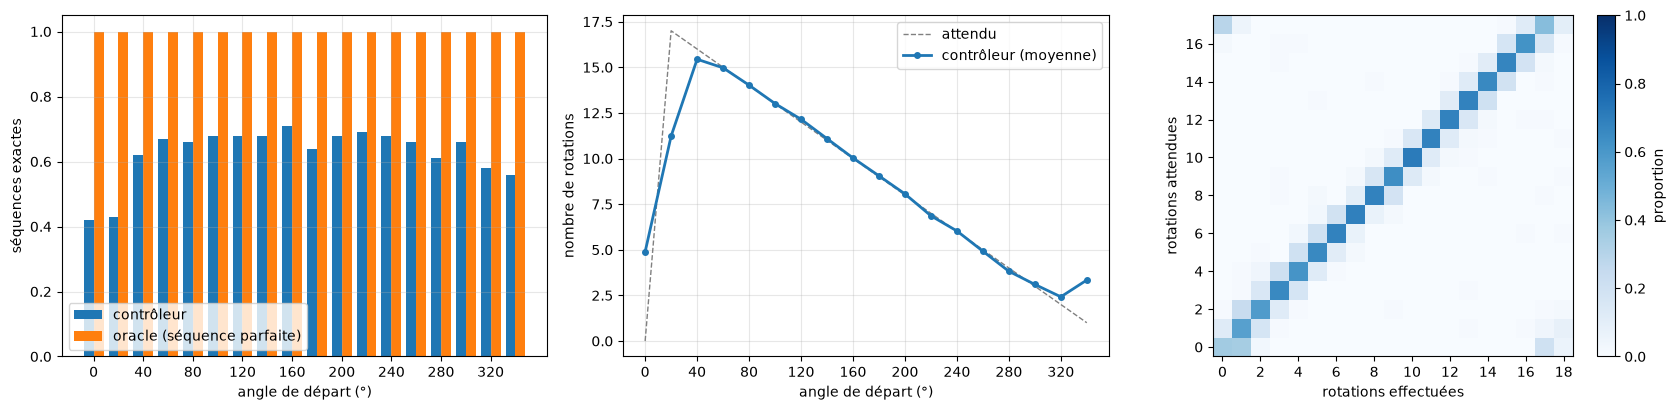

In [3]:
# --- 2. Selon l'angle de départ ---
start_angles = (torch.arange(N_ANGLES) * DEGREES).tolist()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

# Taux de séquences exactes, contrôleur vs oracle
width = 8
for i, name in enumerate(["contrôleur", "oracle (séquence parfaite)"]):
    rate = [results[name]["exact"][m == k].mean().item() for k in range(N_ANGLES)]
    axes[0].bar([a + (i - 0.5) * width for a in start_angles], rate, width, label=name, color=f"C{i}")
axes[0].set_xlabel("angle de départ (°)")
axes[0].set_ylabel("séquences exactes")
axes[0].set_ylim(0, 1.05)
axes[0].set_xticks(start_angles[::2])
axes[0].legend(loc="lower left")

# Nombre de rotations effectuées vs attendu
performed = n_rotations["contrôleur"].float()
mean_performed = [performed[m == k].mean().item() for k in range(N_ANGLES)]
axes[1].plot(start_angles, [((-k) % N_ANGLES) for k in range(N_ANGLES)], color="gray", linestyle="--", linewidth=1, label="attendu")
axes[1].plot(start_angles, mean_performed, marker="o", markersize=4, linewidth=2, color="C0", label="contrôleur (moyenne)")
axes[1].set_xlabel("angle de départ (°)")
axes[1].set_ylabel("nombre de rotations")
axes[1].set_xticks(start_angles[::2])
axes[1].legend()

# Matrice de confusion : rotations attendues (lignes) vs effectuées (colonnes)
confusion = torch.zeros(N_ANGLES, model.hparams.max_steps + 1)
for e, p in zip(expected.tolist(), n_rotations["contrôleur"].tolist()):
    confusion[e, p] += 1
confusion = confusion / confusion.sum(1, keepdim=True)
im = axes[2].imshow(confusion, cmap="Blues", vmin=0, vmax=1, origin="lower")
axes[2].set_xlabel("rotations effectuées")
axes[2].set_xticks(range(0, model.hparams.max_steps + 1, 2))
axes[2].set_yticks(range(0, N_ANGLES, 2))
axes[2].set_ylabel("rotations attendues")
fig.colorbar(im, ax=axes[2], label="proportion")

for ax in axes[:2]:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

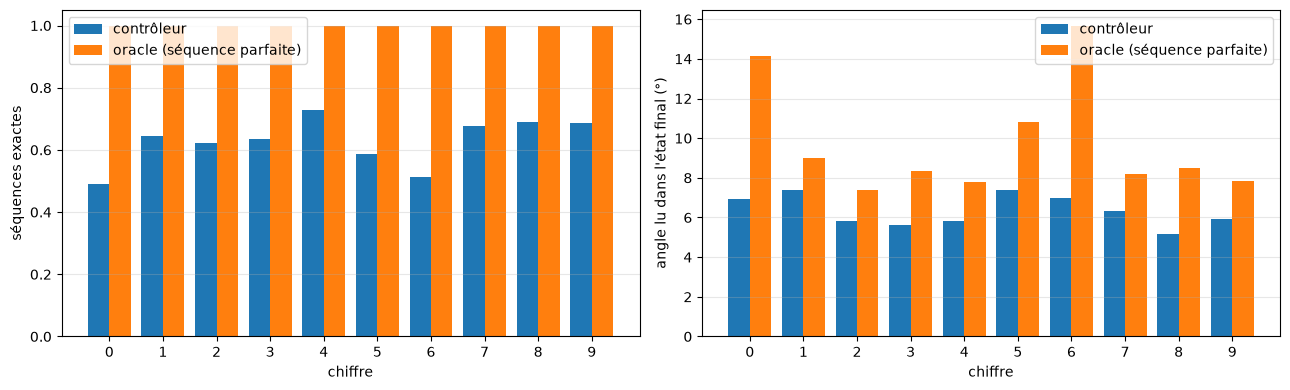

In [4]:
# --- 3. Chiffre par chiffre ---
# 0, 1 et 8 sont presque symétriques par rotation de 180° : leur orientation est ambiguë.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
width = 0.4
for i, name in enumerate(["contrôleur", "oracle (séquence parfaite)"]):
    for ax, metric in zip(axes, ["exact", "angle lu (°)"]):
        values = [results[name][metric][labels == d].mean().item() for d in range(BASE)]
        ax.bar(torch.arange(BASE) + (i - 0.5) * width, values, width, label=name, color=f"C{i}")
axes[0].set_ylabel("séquences exactes")
axes[0].set_ylim(0, 1.05)
axes[1].set_ylabel("angle lu dans l'état final (°)")
for ax in axes:
    ax.set_xticks(range(BASE))
    ax.set_xlabel("chiffre")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

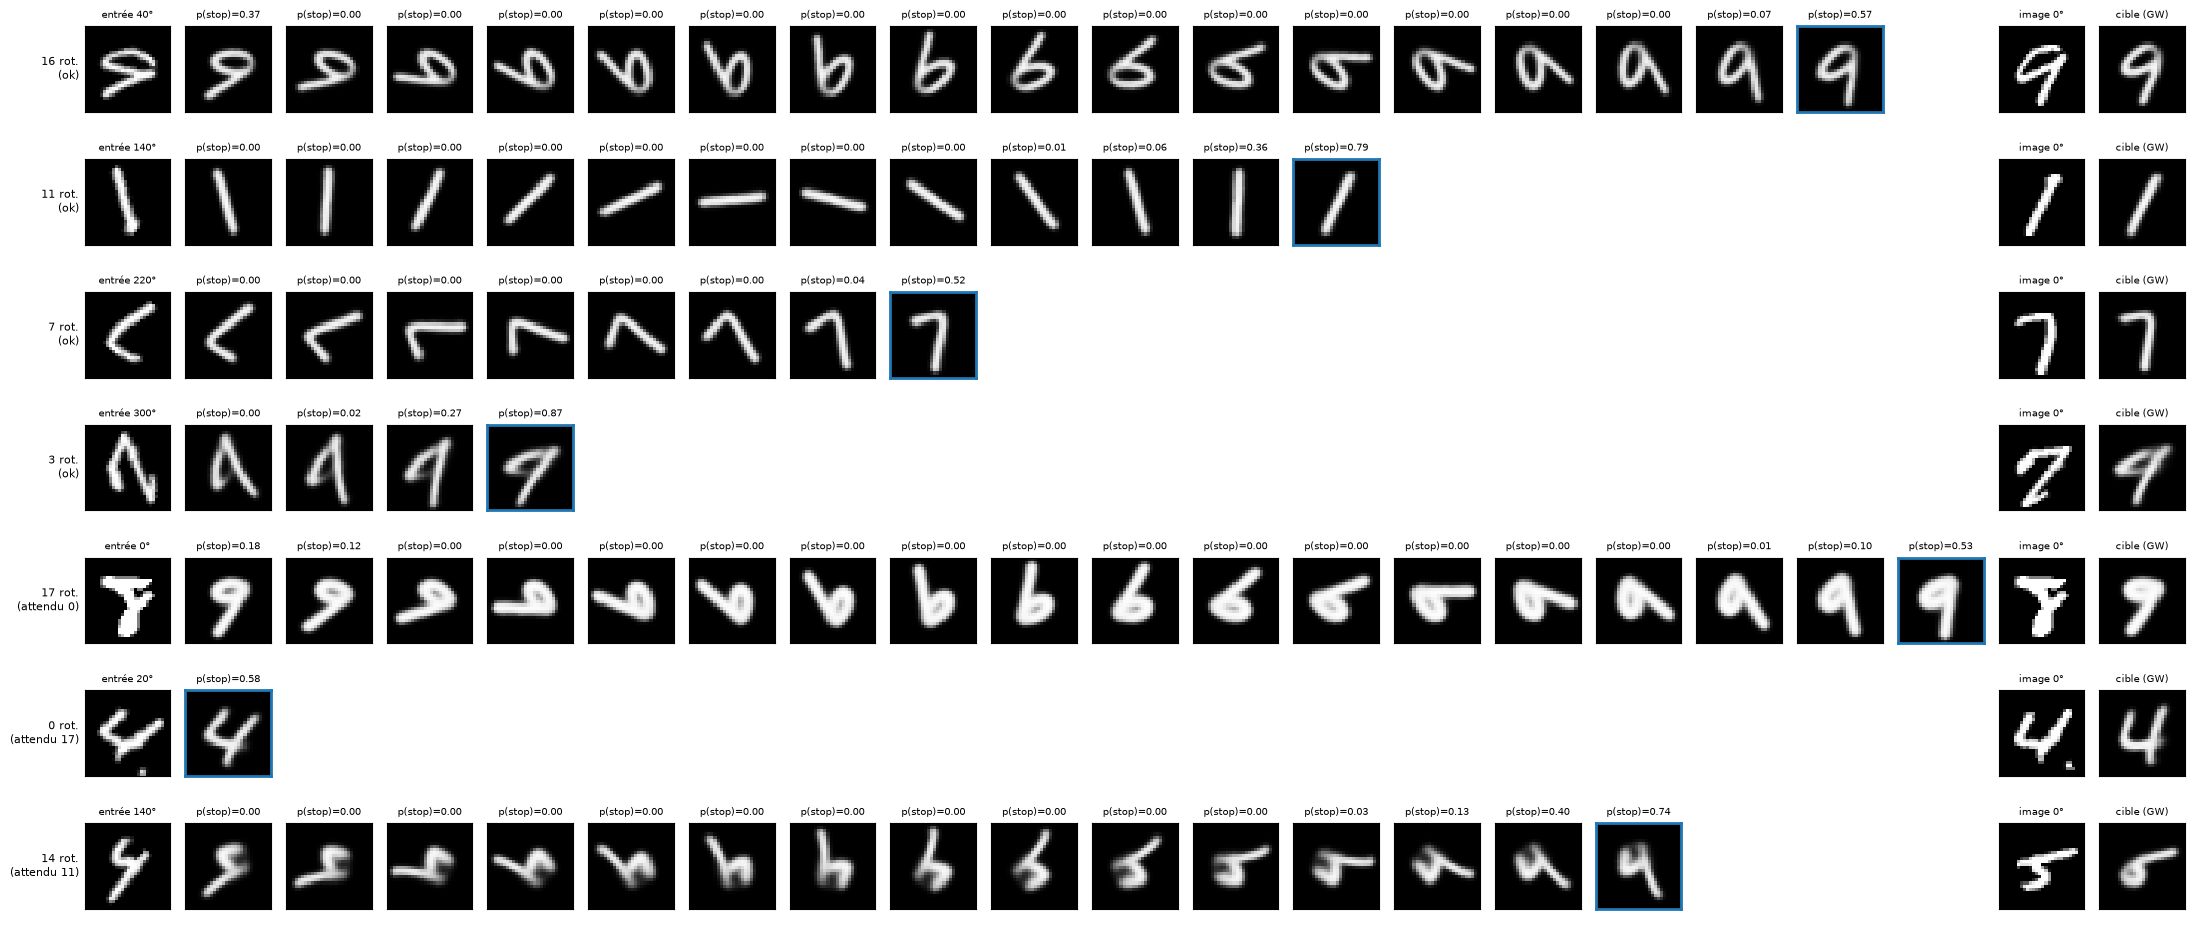

In [5]:
# --- 4. Trajectoires ---
# Une ligne par image : entrée tournée, puis l'état du GW décodé en image avant
# chaque choix (titre : probabilité de stop), jusqu'à l'état final (cadre) ;
# deux dernières colonnes : image d'origine à 0° et sa projection dans le GW
# (encodeur image seul), décodée en image : la cible.
def show_trajectories(indices):
    states, stop_probs = chain["states"][indices], chain["stop_probs"][indices]
    n_steps = n_rotations["contrôleur"][indices]
    n_cols = int(n_steps.max()) + 4
    fig, axes = plt.subplots(len(indices), n_cols, figsize=(n_cols * 1.05, 1.35 * len(indices)), squeeze=False)
    for r, i in enumerate(indices):
        decoded = gw_to_image(gw, states[r, : n_steps[r] + 1])
        panels = [(rotated[i], f"entrée {m[i] * DEGREES:.0f}°")]
        panels += [(decoded[t], f"p(stop)={stop_probs[r, t]:.2f}") for t in range(n_steps[r] + 1)]
        for c in range(n_cols):
            ax = axes[r, c]
            ax.set_xticks([]); ax.set_yticks([])
            if c < len(panels):
                image, title = panels[c]
                ax.imshow(image[0].cpu(), cmap="gray", vmin=0, vmax=1)
                ax.set_title(title, fontsize=7)
                if c == len(panels) - 1:  # état final, après stop
                    for spine in ax.spines.values():
                        spine.set_color("C0"); spine.set_linewidth(2)
            elif c == n_cols - 2:
                ax.imshow(images[i, 0].cpu(), cmap="gray", vmin=0, vmax=1)
                ax.set_title("image 0°", fontsize=7)
            elif c == n_cols - 1:
                ax.imshow(gw_to_image(gw, target[i : i + 1])[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
                ax.set_title("cible (GW)", fontsize=7)
            else:
                ax.axis("off")
        ok = "ok" if n_steps[r] == expected[i] else f"attendu {expected[i]}"
        axes[r, 0].set_ylabel(f"{n_steps[r]} rot.\n({ok})", fontsize=8, rotation=0, ha="right", va="center")
    plt.tight_layout()
    plt.show()


# Angles de départ variés, réussites et échecs
correct = n_rotations["contrôleur"] == expected
picked = [int(torch.nonzero((m == k) & correct)[0]) for k in (2, 7, 11, 15) if ((m == k) & correct).any()]
picked += [int(i) for i in torch.nonzero(~correct)[:3].flatten()]
show_trajectories(picked)

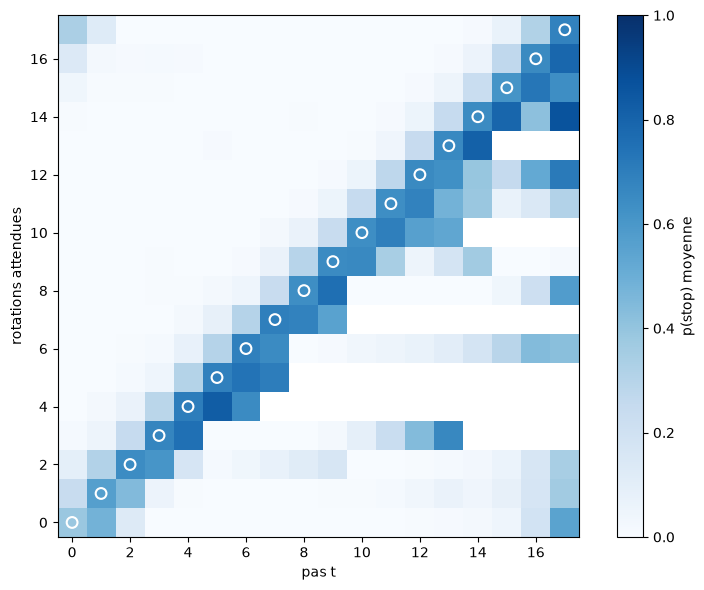

In [6]:
# --- 5. Probabilité de stop pas à pas ---
# Moyenne de p(stop) au pas t (en ligne : rotations attendues). Un contrôleur
# idéal a p(stop) ~ 0 avant le pas attendu (case blanche cerclée) et ~ 1 dessus.
# Les pas après un stop n'ont pas d'effet et sont masqués.
alive = torch.arange(model.hparams.max_steps, device=m.device).unsqueeze(0) <= n_rotations["contrôleur"].unsqueeze(1)
probs = torch.full((N_ANGLES, model.hparams.max_steps), float("nan"))
for k in range(N_ANGLES):
    rows = expected == k
    p, a = chain["stop_probs"][rows], alive[rows].float()
    probs[k] = ((p * a).sum(0) / a.sum(0)).cpu()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(probs, cmap="Blues", vmin=0, vmax=1, origin="lower")
ax.scatter(range(N_ANGLES), range(N_ANGLES), s=60, facecolors="none", edgecolors="white", linewidths=1.5)
ax.set_xlabel("pas t")
ax.set_ylabel("rotations attendues")
fig.colorbar(im, ax=ax, label="p(stop) moyenne")
plt.tight_layout()
plt.show()